# Лабораторная работа 3. Анализ сетевого трафика

## Часть 2. Таксономия сетевых атак

**Выполнил(а):** Ниязов Никита и Зверев Егор
**Группа:** ИНБб-4301-02-00

---

В части 1 мы отличали нормальный трафик от «какой-то атаки». Но для аналитика безопасности этого мало: реакция на сканирование портов и на подбор пароля — разная. Здесь мы решаем **задачу мультиклассовой классификации**: определяем **категорию** атаки по признакам соединения.

Заодно разберём, как правильно оценивать качество IDS: внутреннее разбиение train/test даёт обманчиво высокие цифры, а честный протокол NSL-KDD (обучение на `KDDTrain+`, проверка на отдельном `KDDTest+`) показывает, что происходит с классификатором на **новых, незнакомых типах атак**.

## Шаг 0. Подключение датасета

Тот же, что в блокноте 01. Если папка `datasets/` уже рядом с блокнотом (локально) или распакована в `/content/` (Colab) — просто выполните проверочную ячейку.

In [3]:
from google.colab import drive
drive.mount('/content/drive')
!unzip -q "/content/drive/MyDrive/datasets.zip" -d /content/


Mounted at /content/drive


In [4]:
import os

DATA_DIR = 'datasets' if os.path.isdir('datasets') else '/content/datasets'

for name in ['ids.csv', 'KDDTrain+.csv', 'KDDTest+.csv']:
    path = os.path.join(DATA_DIR, name)
    assert os.path.isfile(path), (
        f'Файл {name} не найден по пути {path}. '
        'В Colab выполните ячейку «Шаг 0», локально — положите папку datasets рядом с блокнотом.')

print('Датасеты на месте:', sorted(os.listdir(DATA_DIR)))

Датасеты на месте: ['KDDTest+.csv', 'KDDTrain+.csv', 'ids.csv']


In [6]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay)

RANDOM_STATE = 2

## Шаг 1. Загрузка KDDTrain+

Полный тренировочный набор NSL-KDD — **125 973 соединения**. Файл без строки заголовка, поэтому имена 43 столбцов задаём вручную: 41 признак (та же схема, что в части 1), затем `label` — метка (конкретный тип атаки или `normal`), и последний столбец `difficulty` — искусственный показатель «сложности» записи, оставшийся от процедуры улучшения NSL-KDD; в анализе он **не участвует**.

In [7]:
COLS = ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes',
        'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in',
        'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations',
        'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login',
        'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate',
        'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate',
        'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
        'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
        'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate',
        'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'label', 'difficulty']

data = pd.read_csv(os.path.join(DATA_DIR, 'KDDTrain+.csv'), header=None, names=COLS)
print('Размер:', data.shape)
data.head(3)

Размер: (125973, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.0,0.0,0.0,0.05,0.0,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.0,0.0,0.0,0.00,0.0,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.0,1.0,1.0,0.00,0.0,neptune,19


In [8]:
# Сколько и каких типов атак в тренировочном наборе
print('Различных меток:', data['label'].nunique())
print()
print(data['label'].value_counts().to_string())

Различных меток: 23

label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2


## Шаг 2. Таксономия: 22 типа атак → 4 категории

Учить классификатор различать 23 метки — плохая идея: на некоторые типы атак приходятся **единицы** записей (`perl` — 3, `spy` — 2). Поэтому в NSL-KDD типы атак группируют в **4 категории**:

| Категория | Расшифровка | Суть | Примеры типов |
|---|---|---|---|
| `dos` | Denial of Service | отказ в обслуживании: «затопление» сервера трафиком | neptune, smurf, teardrop |
| `probe` | probing | разведка: сканирование портов и уязвимостей | satan, ipsweep, nmap |
| `r2l` | Remote to Local | неавторизованный доступ с удалённой машины | guess_passwd, warezclient |
| `u2r` | User to Root | повышение привилегий до суперпользователя | buffer_overflow, rootkit |

Плюс пятый класс — `normal`. Получаем задачу классификации на **5 классов**. В словарь ниже включены и типы атак, которые встретятся только в тестовом наборе (шаг 6).

In [11]:
ATTACK_CATEGORY = {
    'normal': 'normal',
    # dos — отказ в обслуживании
    'neptune': 'dos', 'smurf': 'dos', 'back': 'dos', 'teardrop': 'dos',
    'pod': 'dos', 'land': 'dos', 'apache2': 'dos', 'udpstorm': 'dos',
    'processtable': 'dos', 'mailbomb': 'dos', 'worm': 'dos',
    # probe — разведка и сканирование
    'satan': 'probe', 'ipsweep': 'probe', 'portsweep': 'probe',
    'nmap': 'probe', 'mscan': 'probe', 'saint': 'probe',
    # r2l — неавторизованный доступ с удалённой машины
    'warezclient': 'r2l', 'guess_passwd': 'r2l', 'warezmaster': 'r2l',
    'imap': 'r2l', 'ftp_write': 'r2l', 'multihop': 'r2l', 'phf': 'r2l',
    'spy': 'r2l', 'httptunnel': 'r2l', 'snmpguess': 'r2l',
    'snmpgetattack': 'r2l', 'named': 'r2l', 'sendmail': 'r2l',
    'xlock': 'r2l', 'xsnoop': 'r2l',
    # u2r — повышение привилегий до root
    'buffer_overflow': 'u2r', 'rootkit': 'u2r', 'loadmodule': 'u2r',
    'perl': 'u2r', 'ps': 'u2r', 'sqlattack': 'u2r', 'xterm': 'u2r',
}

data['category'] = data['label'].map(ATTACK_CATEGORY)
assert data['category'].notna().all(), 'Есть метки без категории — проверьте словарь'

cat_counts = data['category'].value_counts()
print(cat_counts.to_string())
print()
print('Доли: ' + ', '.join(f'{k} {v / len(data):.1%}' for k, v in cat_counts.items()))

category
normal    67343
dos       45927
probe     11656
r2l         995
u2r          52

Доли: normal 53.5%, dos 36.5%, probe 9.3%, r2l 0.8%, u2r 0.0%


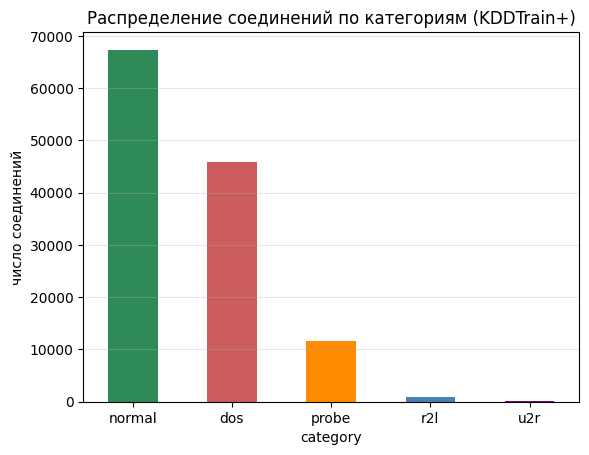

In [10]:
cat_counts.plot.bar(color=['seagreen', 'indianred', 'darkorange', 'steelblue', 'purple'])
plt.title('Распределение соединений по категориям (KDDTrain+)')
plt.ylabel('число соединений')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show()

Во сколько примерно раз записей `dos` больше, чем `u2r`? Что это означает для recall класса `u2r`?

Обратите внимание: в отличие от части 1, классы здесь **сильно несбалансированы** — это гораздо ближе к реальности. Поэтому смотреть будем не на accuracy, а на precision/recall **по каждому классу** (`classification_report`).

Больше примерно в 883 раза (45 927 (dos) / 52 (u2r) ≈ 883).
Для recall это означает, что recall по u2r будет очень низким (близким к нулю): модель пропустит почти все реальные атаки повышения привилегий, так как их сигнал теряется в общем шуме.

## Шаг 3. Предобработка

Схема та же, что в части 1: категориальные признаки → `OrdinalEncoder`, числовые → `MinMaxScaler`, разбиение со стратификацией. Два отличия:

1. столбец `difficulty` выбрасываем вместе с метками;
2. `handle_unknown='use_encoded_value'` здесь **обязателен**: в KDDTrain+ есть 70 различных сервисов, и редкие из них могут попасть в тестовую часть, не встретившись в тренировочной (проверено: без этого параметра — `ValueError: Found unknown categories`).

In [15]:
X = data.drop(columns=['label', 'difficulty', 'category'])
y = data['category']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(f'train: {X_train.shape[0]} соединений, test: {X_test.shape[0]} соединений')
print()
print('train:', y_train.value_counts().to_dict())
print('test: ', y_test.value_counts().to_dict())

train: 100778 соединений, test: 25195 соединений

train: {'normal': 53874, 'dos': 36741, 'probe': 9325, 'r2l': 796, 'u2r': 42}
test:  {'normal': 13469, 'dos': 9186, 'probe': 2331, 'r2l': 199, 'u2r': 10}


In [16]:
cat_cols = ['protocol_type', 'service', 'flag']
num_cols = [c for c in X.columns if c not in cat_cols]

preprocess = ColumnTransformer([
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols),
    ('num', MinMaxScaler(), num_cols),
])

## Шаг 4. k-NN классификатор

Обучим k-NN: 5 классов, честная предобработка, стратифицированное разбиение.

In [17]:
model_knn = make_pipeline(preprocess, KNeighborsClassifier(n_neighbors=5, n_jobs=-1))

t0 = time.time()
model_knn.fit(X_train, y_train)
t1 = time.time()
y_pred = model_knn.predict(X_test)
t2 = time.time()

print(f'Обучение: {t1 - t0:.1f} с, прогноз на {len(X_test)} соединений: {t2 - t1:.1f} с')
print(f'Accuracy: {accuracy_score(y_test, y_pred):.3f}')
print()
print(classification_report(y_test, y_pred, digits=3, zero_division=0))

Обучение: 0.4 с, прогноз на 25195 соединений: 23.2 с
Accuracy: 0.994

              precision    recall  f1-score   support

         dos      0.995     0.999     0.997      9186
      normal      0.996     0.996     0.996     13469
       probe      0.992     0.976     0.984      2331
         r2l      0.929     0.915     0.922       199
         u2r      0.600     0.300     0.400        10

    accuracy                          0.994     25195
   macro avg      0.902     0.837     0.860     25195
weighted avg      0.994     0.994     0.994     25195



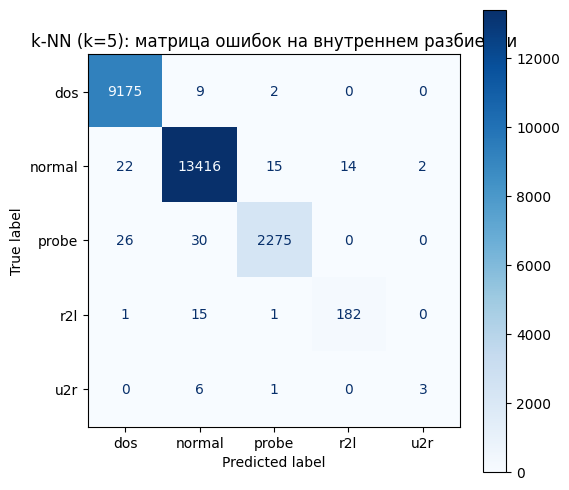

In [18]:
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap='Blues')
plt.title('k-NN (k=5): матрица ошибок на внутреннем разбиении')
plt.grid(False)
plt.show()

Accuracy около 99 % — похоже на часть 1. Но посмотрите на строку `u2r` в отчёте: на 10 тестовых примерах полнота неустойчива. Возникает вопрос: **означают ли 99 %, что классификатор готов к обработке реального трафика?**

Нет, accuracy 99.4% не означает готовность к реальному трафику.
По матрице ошибок видно, что из 10 реальных атак u2r модель распознала только 3, а 7 (70%) пропустила (6 ушли в normal, 1 в probe). При этом precision для u2r составляет всего 0.6, то есть 40% тревог — ложные.


## Шаг 5. Решающее дерево для сравнения

Проверим, не является ли результат особенностью k-NN. Обучим дерево решений на тех же данных.

In [19]:
model_tree = make_pipeline(preprocess, DecisionTreeClassifier(random_state=RANDOM_STATE))

t0 = time.time()
model_tree.fit(X_train, y_train)
y_pred_tree = model_tree.predict(X_test)
print(f'Обучение: {time.time() - t0:.1f} с')
print(f'Accuracy: {accuracy_score(y_test, y_pred_tree):.3f}')
print()
print(classification_report(y_test, y_pred_tree, digits=3, zero_division=0))

Обучение: 1.6 с
Accuracy: 0.997

              precision    recall  f1-score   support

         dos      0.999     0.999     0.999      9186
      normal      0.998     0.998     0.998     13469
       probe      0.993     0.995     0.994      2331
         r2l      0.974     0.950     0.962       199
         u2r      0.429     0.600     0.500        10

    accuracy                          0.997     25195
   macro avg      0.879     0.908     0.891     25195
weighted avg      0.998     0.997     0.998     25195



## Шаг 6. Честная проверка: тестовый набор KDDTest+

Внутреннее разбиение 80/20 похоже на экзамен по билетам: тестовые соединения взяты из того же распределения, что и тренировочные. Реальной IDS встречаются **новые типы атак**, которых не было при обучении.

Стандартный протокол оценки NSL-KDD устроен строже:

- обучение — на **всём** `KDDTrain+` (126 тыс. соединений, 22 типа атак);
- проверка — на отдельном наборе `KDDTest+` (22,5 тыс. соединений), который содержит **15 дополнительных типов атак**, отсутствующих в train.

Посмотрим сначала, что это за новые атаки.

In [20]:
test_data = pd.read_csv(os.path.join(DATA_DIR, 'KDDTest+.csv'), header=None, names=COLS)
test_data['category'] = test_data['label'].map(ATTACK_CATEGORY)
assert test_data['category'].notna().all()

new_attacks = sorted(set(test_data['label']) - set(data['label']))
print(f'Типов меток в тесте: {test_data["label"].nunique()}, из них новых (нет в train): {len(new_attacks)}')
print('Новые типы атак:', ', '.join(new_attacks))
print()
print(test_data['category'].value_counts().to_string())

Типов меток в тесте: 38, из них новых (нет в train): 17
Новые типы атак: apache2, httptunnel, mailbomb, mscan, named, processtable, ps, saint, sendmail, snmpgetattack, snmpguess, sqlattack, udpstorm, worm, xlock, xsnoop, xterm

category
normal    9710
dos       7460
r2l       2885
probe     2421
u2r         67


In [21]:
# Переобучаем обе модели на ВСЁМ тренировочном наборе и проверяем на KDDTest+
X_full, y_full = X, y
X_test_real, y_test_real = (test_data.drop(columns=['label', 'difficulty', 'category']),
                            test_data['category'])

models_real = {}
for name, make_model in [('k-NN (k=5)', lambda: KNeighborsClassifier(n_neighbors=5, n_jobs=-1)),
                         ('Дерево решений', lambda: DecisionTreeClassifier(random_state=RANDOM_STATE))]:
    model = make_pipeline(preprocess, make_model())
    t0 = time.time()
    model.fit(X_full, y_full)
    acc = model.score(X_test_real, y_test_real)
    models_real[name] = model
    print(f'{name}: обучение {time.time() - t0:.1f} с, accuracy на KDDTest+ = {acc:.3f}')

k-NN (k=5): обучение 26.4 с, accuracy на KDDTest+ = 0.738
Дерево решений: обучение 6.4 с, accuracy на KDDTest+ = 0.769


In [23]:
# Подробный отчёт для лучшей модели (дерево решений)
y_pred_real = models_real['Дерево решений'].predict(X_test_real)
print(classification_report(y_test_real, y_pred_real, digits=3, zero_division=0))

              precision    recall  f1-score   support

         dos      0.954     0.828     0.886      7460
      normal      0.700     0.966     0.811      9710
       probe      0.642     0.634     0.638      2421
         r2l      0.941     0.083     0.152      2885
         u2r      0.571     0.179     0.273        67

    accuracy                          0.769     22543
   macro avg      0.762     0.538     0.552     22543
weighted avg      0.808     0.769     0.732     22543



Сравните accuracy на внутреннем разбиении (~99 %) и на KDDTest+ (~78 %). Куда «пропали» 20 процентных пунктов? Посмотрите на recall классов `r2l` и `u2r`: что с ними стало и почему?

Объяснение (сверьтесь с вашими предположениями):

- В тестовом наборе **новые типы атак** (mscan, apache2, snmpguess и др.) — их соединения классификатор никогда не видел и относит к похожим знакомым классам, часто к `normal`.
- **Распределения категорий сдвинуты**: в тесте доля `r2l` заметно выше, чем в train, а это самая трудная категория (её признаки похожи на нормальный трафик — например, `guess_passwd` внешне выглядит как обычные попытки входа).
- Внутреннее разбиение измеряет «узнала ли модель знакомые атаки», а честный протокол — «заметит ли она незнакомые». Это разные вопросы, и для IDS важнее второй.

## Выводы по части 2

Сформулируйте прямо в этой ячейке:

1. Чем задача этой части отличается от задачи части 1 и почему 23 метки пришлось свести к 5 категориям?
в части 1 это была бинарная классификация, где все типы атак были сведены в один класс anomaly, то есть требовалось просто отличить «нормальное» от «атакующего». В части 2 обучение на всём KDDTrain+ (22 типа атак), проверка на отдельном KDDTest+, в котором есть 17 новых типов атак, отсутствовавших в train. 23 метки пришлось свести к 5 категориям, потому что отдельных типов атак слишком много и часть из них представлена единичными примерами. Пять категорий (normal, dos, probe, r2l, u2r) — это стандартная таксономия, которая сохраняет содержательный смысл угроз (отказ в обслуживании, разведка, удалённый неавторизованный доступ и повышение привилегий).
2. Какие классы распознаются хуже всего на честном тесте и почему?
Хуже всего на честном тесте распознаются r2l и u2r. У дерева решений recall r2l составил 0,083 при precision 0,941, recall u2r — 0,179 при precision 0,571.  
 В KDDTest+ как раз много новых типов атак, которых не было в train, и для r2l и u2r это особенно чувствительно, модель никогда их не видела и относит к знакомым классам, чаще всего к normal. В результате высокая precision при низком recall означает, что те немногие объекты, которые модель назвала r2l или u2r, действительно относятся к этим классам, но подавляющее большинство реальных атак этих категорий пропускается.
3. Что показал протокол «KDDTrain+ → KDDTest+» по сравнению с внутренним разбиением? Какой вывод для практики оценки ML-моделей в безопасности?
Протокол «KDDTrain+ → KDDTest+» показал, что внутреннее разбиение 80/20 брало тестовые соединения из того же распределения, что и обучающие, и по сути проверяло, узнаёт ли модель знакомые атаки; отсюда accuracy около 99% у k-NN и дерева. 20 процентных пунктов пропали, потому что внутреннее разбиение измеряло лёгкую задачу, а KDDTest+ — реалистичную, с новыми типами атак и сдвинутым распределением категорий, где доля трудного r2l заметно выше.
Для оценки ML-моделей в безопасности нельзя доверять accuracy на случайном разбиении одного и того же распределения, потому что она завышена и не отражает поведение на новых угрозах; нужно использовать честные протоколы с отдельными тестовыми наборами, включающими незнакомые атаки; для реальной эксплуатации нужны более свежие данные, проверка на дрейф трафика и состязательную устойчивость.

**Вопросы (необязательные)):**

- Почему для категорий `r2l` и `u2r` полнота низкая даже при высокой общей accuracy? Какой приём из ЛР № 2 помог бы сдвинуть баланс в пользу редких классов (подсказка: `class_weight`)?
- В тестовом наборе атаки `worm` всего 2 записи. Что покажет для такого класса `classification_report` и насколько этим цифрам можно верить?
- Предложите способ улучшить обнаружение *незнакомых* атак, не перечисленных в обучающей выборке. (Подсказка: вспомните про обучение без учителя и выявление аномалий — методичка, Приложение А.)

---

➡️ Не забудьте выполнить **индивидуальное задание** (методичка, раздел 5 и Приложение Г) и оформить сдачу в Git.